In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("/content/Flight_Booking.csv")

In [ ]:
df

,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955
...,...,...,...,...,...,...,...,...,...,...,...,...
300148,300148,Vistara,UK-822,Chennai,Morning,one,Evening,Hyderabad,Business,10.08,49,69265
300149,300149,Vistara,UK-826,Chennai,Afternoon,one,Night,Hyderabad,Business,10.42,49,77105
300150,300150,Vistara,UK-832,Chennai,Early_Morning,one,Night,Hyderabad,Business,13.83,49,79099
300151,300151,Vistara,UK-828,Chennai,Early_Morning,one,Evening,Hyderabad,Business,10.00,49,81585


In [ ]:
#info,describe,null,duplicate

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        300153 non-null  int64  
 1   airline           300153 non-null  object 
 2   flight            300153 non-null  object 
 3   source_city       300153 non-null  object 
 4   departure_time    300153 non-null  object 
 5   stops             300153 non-null  object 
 6   arrival_time      300153 non-null  object 
 7   destination_city  300153 non-null  object 
 8   class             300153 non-null  object 
 9   duration          300153 non-null  float64
 10  days_left         300153 non-null  int64  
 11  price             300153 non-null  int64  
dtypes: float64(1), int64(3), object(8)
memory usage: 27.5+ MB


In [ ]:
df.drop("Unnamed: 0",axis=1,inplace=True)

In [ ]:
df.head()

,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


In [ ]:
df.describe()

,duration,days_left,price
count,300153.000000,300153.000000,300153.000000
mean,12.221021,26.004751,20889.660523
std,7.191997,13.561004,22697.767366
min,0.830000,1.000000,1105.000000
25%,6.830000,15.000000,4783.000000
50%,11.250000,26.000000,7425.000000
75%,16.170000,38.000000,42521.000000
max,49.830000,49.000000,123071.000000


In [ ]:
df.describe(include="O")

,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class
count,300153,300153,300153,300153,300153,300153,300153,300153
unique,6,1561,6,6,3,6,6,2
top,Vistara,UK-706,Delhi,Morning,one,Night,Mumbai,Economy
freq,127859,3235,61343,71146,250863,91538,59097,206666


In [ ]:
df.isnull().sum()

,0
airline,0
flight,0
source_city,0
departure_time,0
stops,0
arrival_time,0
destination_city,0
class,0
duration,0
days_left,0


In [ ]:
df.duplicated().sum()

np.int64(0)

Data Visualization

In [ ]:
#line plot to show variation in price with different airlines

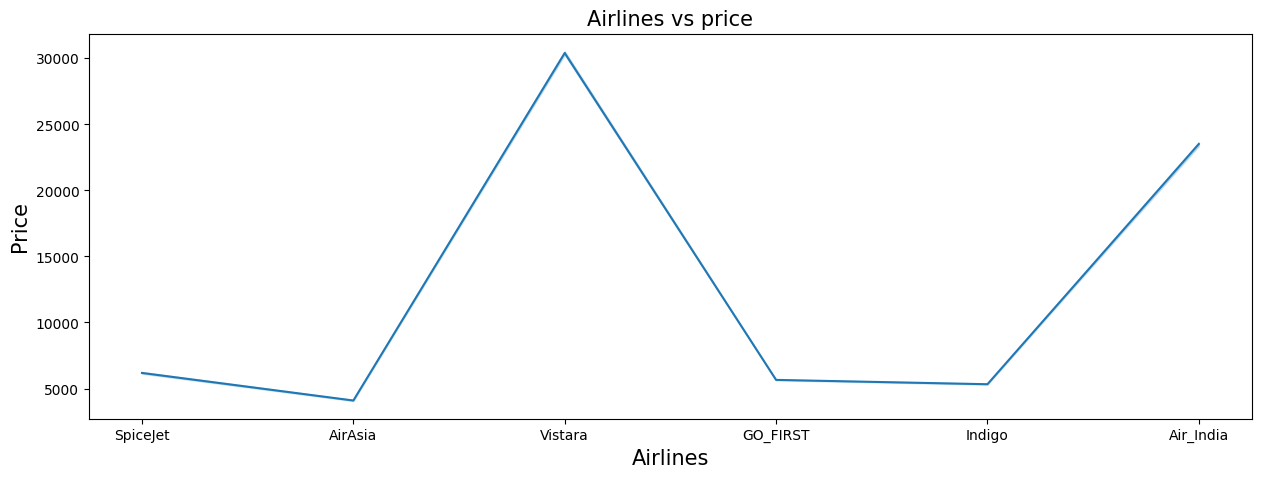

In [ ]:
plt.figure(figsize=(15,5))
sns.lineplot(x=df['airline'],y=df['price'])
plt.title("Airlines vs price",fontsize=15)
plt.xlabel("Airlines",fontsize=15)
plt.ylabel("Price",fontsize=15)
plt.show()

In [ ]:
#Show that The price of ticket increases as the number of left days decreases

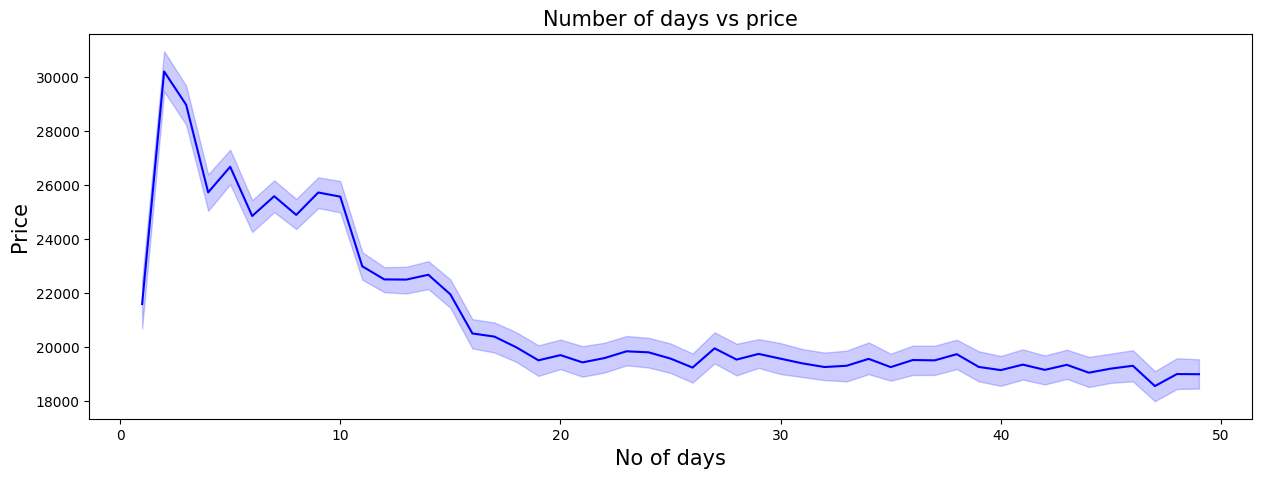

In [ ]:
plt.figure(figsize=(15,5))
sns.lineplot(data=df,x="days_left",y="price",color="blue")
plt.title("Number of days vs price",fontsize=15)
plt.xlabel("No of days",fontsize=15)
plt.ylabel("Price",fontsize=15)
plt.show()

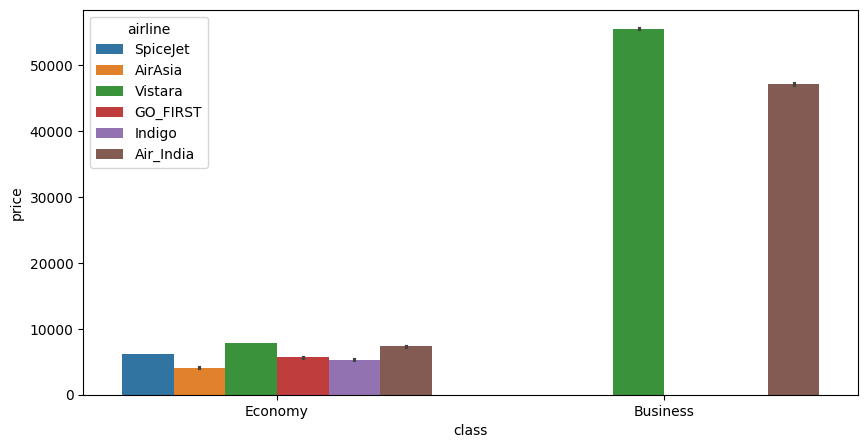

In [ ]:
#Range of prices of all flights of Economy and business class
plt.figure(figsize=(10,5))
sns.barplot(data=df,x="class",y="price",hue="airline")
plt.show()

In [ ]:
#Preprocessing
from sklearn.preprocessing import LabelEncoder

In [ ]:
le = LabelEncoder()

In [ ]:
for i in df.columns:
  if df[i].dtype=="object":
    df[i] = le.fit_transform(df[i])

In [ ]:
df.head(3)

,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,4,1408,2,2,2,5,5,1,2.17,1,5953
1,4,1387,2,1,2,4,5,1,2.33,1,5953
2,0,1213,2,1,2,1,5,1,2.17,1,5956


In [ ]:
#check the correlation

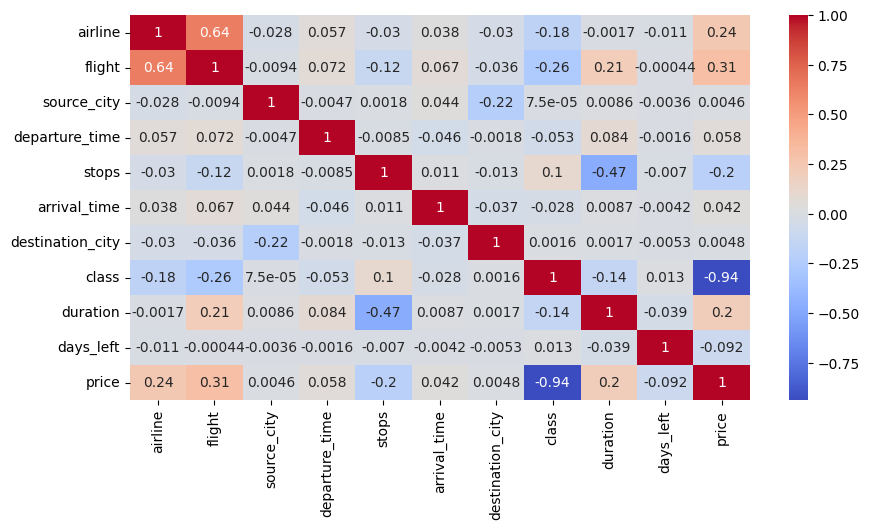

In [ ]:
plt.figure(figsize=(10,5))
sns.heatmap(df.corr(),annot=True,cmap="coolwarm")
plt.show()

In [ ]:
from statsmodels.stats.outliers_influence import  variance_inflation_factor

In [ ]:
col_list = []
for col in df.columns:
  if ((df[col].dtype!="object")& (col != "price")):
    col_list.append(col)

In [ ]:
col_list

['airline',
 'flight',
 'source_city',
 'departure_time',
 'stops',
 'arrival_time',
 'destination_city',
 'class',
 'duration',
 'days_left']

In [ ]:
x = df[col_list]

In [ ]:
x

,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left
0,4,1408,2,2,2,5,5,1,2.17,1
1,4,1387,2,1,2,4,5,1,2.33,1
2,0,1213,2,1,2,1,5,1,2.17,1
3,5,1559,2,4,2,0,5,1,2.25,1
4,5,1549,2,4,2,4,5,1,2.33,1
...,...,...,...,...,...,...,...,...,...,...
300148,5,1477,1,4,0,2,3,0,10.08,49
300149,5,1481,1,0,0,5,3,0,10.42,49
300150,5,1486,1,1,0,5,3,0,13.83,49
300151,5,1483,1,1,0,2,3,0,10.00,49


In [ ]:
vif_data = pd.DataFrame()
vif_data["Features"] = x.columns
vif_data["VIF"] = [variance_inflation_factor(x.values,i) for i in range(len(x.columns))]
vif_data

,Features,VIF
0,airline,6.701818
1,flight,12.675046
2,source_city,2.969540
3,departure_time,2.806009
4,stops,1.437326
5,arrival_time,3.784873
6,destination_city,2.918792
7,class,2.852072
8,duration,4.754588
9,days_left,4.071591


In [ ]:
df.drop("flight",axis=1,inplace=True)

In [ ]:
col_list = []
for col in df.columns:
  if ((df[col].dtype!="object")& (col != "price")):
    col_list.append(col)
x = df[col_list]
vif_data = pd.DataFrame()
vif_data["Features"] = x.columns
vif_data["VIF"] = [variance_inflation_factor(x.values,i) for i in range(len(x.columns))]
vif_data

,Features,VIF
0,airline,3.393124
1,source_city,2.927766
2,departure_time,2.779427
3,stops,1.426614
4,arrival_time,3.684550
5,destination_city,2.885337
6,class,2.849370
7,duration,4.113876
8,days_left,3.976790


In [ ]:
#ModelBuilding

In [ ]:
#1. Linear Regression

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
x = df.drop("price",axis=1)

In [ ]:
y = df["price"]

In [ ]:
xtrain,xtest,ytrain,ytest = train_test_split(x,y,test_size=0.25,random_state=42)

In [ ]:
from sklearn.linear_model import LinearRegression

In [ ]:
model = LinearRegression()

In [ ]:
model.fit(xtrain,ytrain)

LinearRegression()

In [ ]:
result = pd.DataFrame()
result["Actual"] = ytest
ypred = model.predict(xtest)
result["Predicted"] = ypred

In [ ]:
result

,Actual,Predicted
27131,7366,4588.843140
266857,64831,52832.394717
141228,6195,7870.933418
288329,60160,56125.361061
97334,6578,6674.336418
...,...,...
104184,14243,8605.771628
93137,4500,-1398.745702
50649,5232,8113.609692
277630,58315,56406.511756


In [ ]:
from sklearn.metrics import *

In [ ]:
r2_score(ypred,ytest)

0.894932817822307

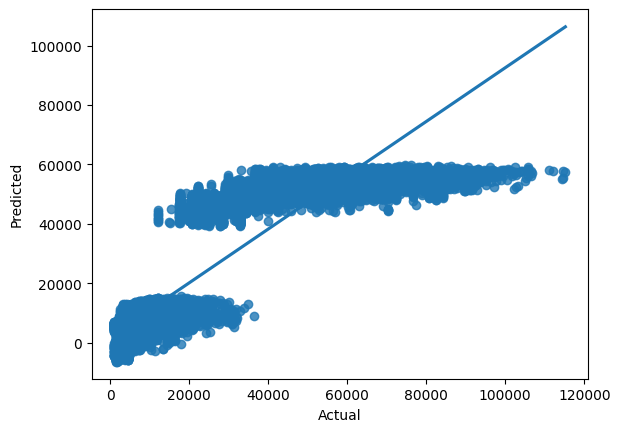

In [ ]:
sns.regplot(data=result,x="Actual",y="Predicted")
plt.show()

In [ ]:
ypred2 = model.predict(xtrain)

In [ ]:
r2_score(ypred2,ytrain)

0.8944852661925079

In [ ]:
mean_squared_error(ypred,ytest)

49105649.45047114

In [ ]:
from sklearn.tree import DecisionTreeRegressor

In [ ]:
model2 = DecisionTreeRegressor()

In [ ]:
model2.fit(xtrain,ytrain)

DecisionTreeRegressor()

In [ ]:
ypred3 = model2.predict(xtest)

In [ ]:
result["Predicted2"] = ypred3

In [ ]:
result

,Actual,Predicted,Predicted2
27131,7366,4588.843140,7366.0
266857,64831,52832.394717,72783.0
141228,6195,7870.933418,6195.0
288329,60160,56125.361061,60160.0
97334,6578,6674.336418,6578.0
...,...,...,...
104184,14243,8605.771628,13054.0
93137,4500,-1398.745702,4500.0
50649,5232,8113.609692,5232.0
277630,58315,56406.511756,58315.0


In [ ]:
r2_score(ypred3,ytest)

0.9756594033073627

In [ ]:
mean_squared_error(ypred3,ytest)

12566971.616396511

In [ ]:
ypred4 = model2.predict(xtrain)

In [ ]:
r2_score(ypred4,ytrain)

0.999314456310176